# <span style="color:rgb(213,80,0)">Plantilla examen de robótica</span>

Primer Examen Parcial de Robótica

Modelado cinemático y dinámico de un robot SCARA

Alumno: Cano Diaz Jose Antonio

Materia: Robótica

Profesor: M.I. Erik Peña Medina

## Resumen

La formulación matemática de un manipulador robótico constituye la base teórica indispensable para comprender su cinemática y su respuesta ante fuerzas externas. En el estudio de un robot planar tipo SCARA de tres grados de libertad rotacionales, deducir sus ecuaciones geométricas y dinámicas permite vincular directamente las coordenadas del espacio articular con la posición, orientación, velocidades, aceleraciones y pares de actuación en el extremo operativo.

El presente trabajo documenta de forma secuencial el modelado analítico del robot desarrollado durante el curso. En primera instancia, se construye la cinemática directa de posición empleando matrices de transformación homogénea sucesivas y se resuelve el problema cinemático inverso por métodos trigonométricos para hallar las configuraciones articulares dada una postura meta. Posteriormente, a través del cálculo de la matriz Jacobiana y su derivada temporal, se establecen las relaciones directas e inversas de velocidad y aceleración. Por último, se aplica la formulación energética de Euler\-Lagrange para obtener las ecuaciones dinámicas del sistema.

**Objetivo:** Desarrollar y validar simbólicamente el modelo cinemático y dinámico integral del manipulador SCARA de tres eslabones, estructurando sus expresiones matriciales para su posterior uso en esquemas de simulación y control.

**Hipótesis:** Mediante la concatenación de matrices de transformación homogénea, el análisis diferencial con el Jacobiano geométrico y el balance energético de Euler\-Lagrange, es posible obtener un sistema cerrado de ecuaciones que describa con exactitud tanto el movimiento directo como la dinámica inversa del manipulador.

Definición de funciones


In [1]:
clear; clc;
%Deficición de la función de manera simbolica
syms Tij(x_i_j,y_i_j,z_i_j,gi_j,bi_j,ai_j)


%Definición de la transformación homógenea general
Tij(x_i_j,y_i_j,z_i_j,gi_j,bi_j,ai_j) = [cos(ai_j)*cos(bi_j) cos(ai_j)*sin(bi_j)*sin(gi_j)-sin(ai_j)*cos(gi_j) sin(ai_j)*sin(gi_j)+cos(ai_j)*sin(bi_j)*cos(gi_j) x_i_j; sin(ai_j)*cos(bi_j) cos(ai_j)*cos(gi_j)+sin(ai_j)*sin(bi_j)*sin(gi_j) sin(ai_j)*sin(bi_j)*cos(gi_j)-cos(ai_j)*sin(gi_j) y_i_j; -sin(bi_j) cos(bi_j)*sin(gi_j) cos(bi_j)*cos(gi_j) z_i_j; 0 0 0 1]


## Modelado del robot Scara

<p style="text-align:left">
   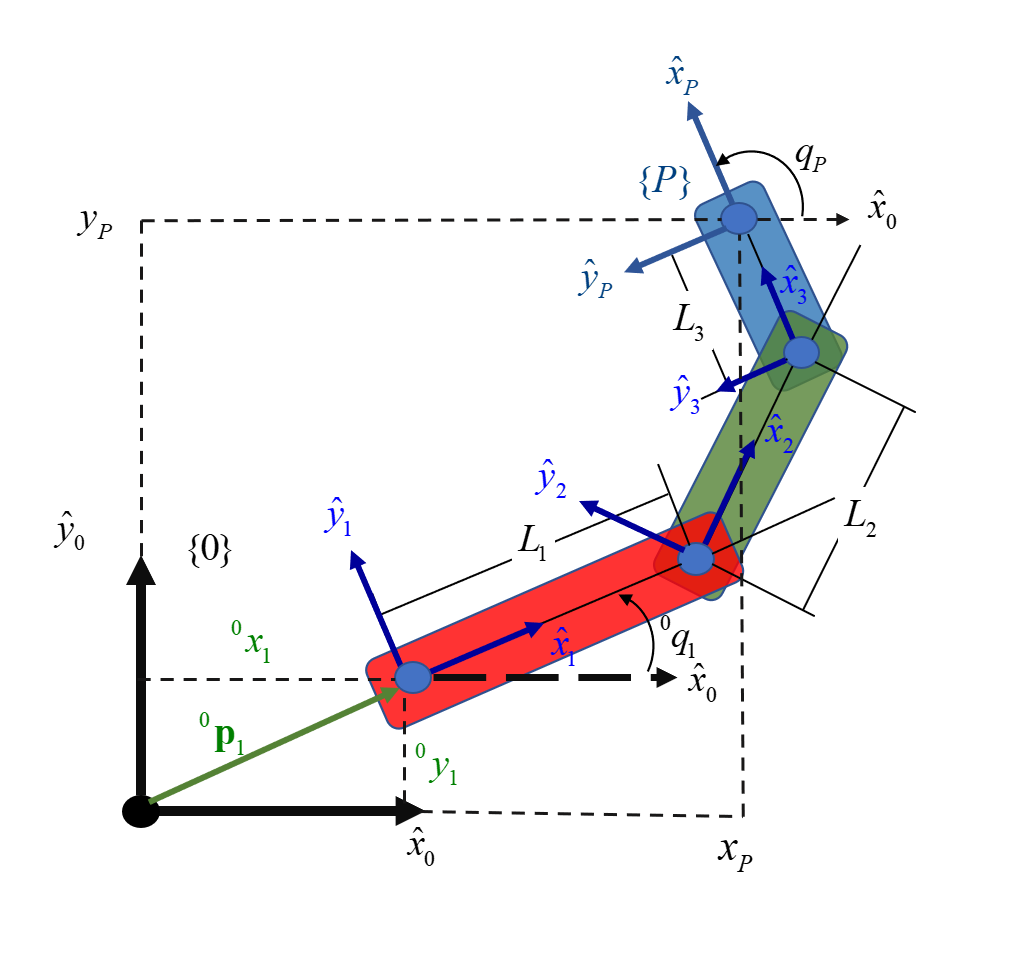
</p>



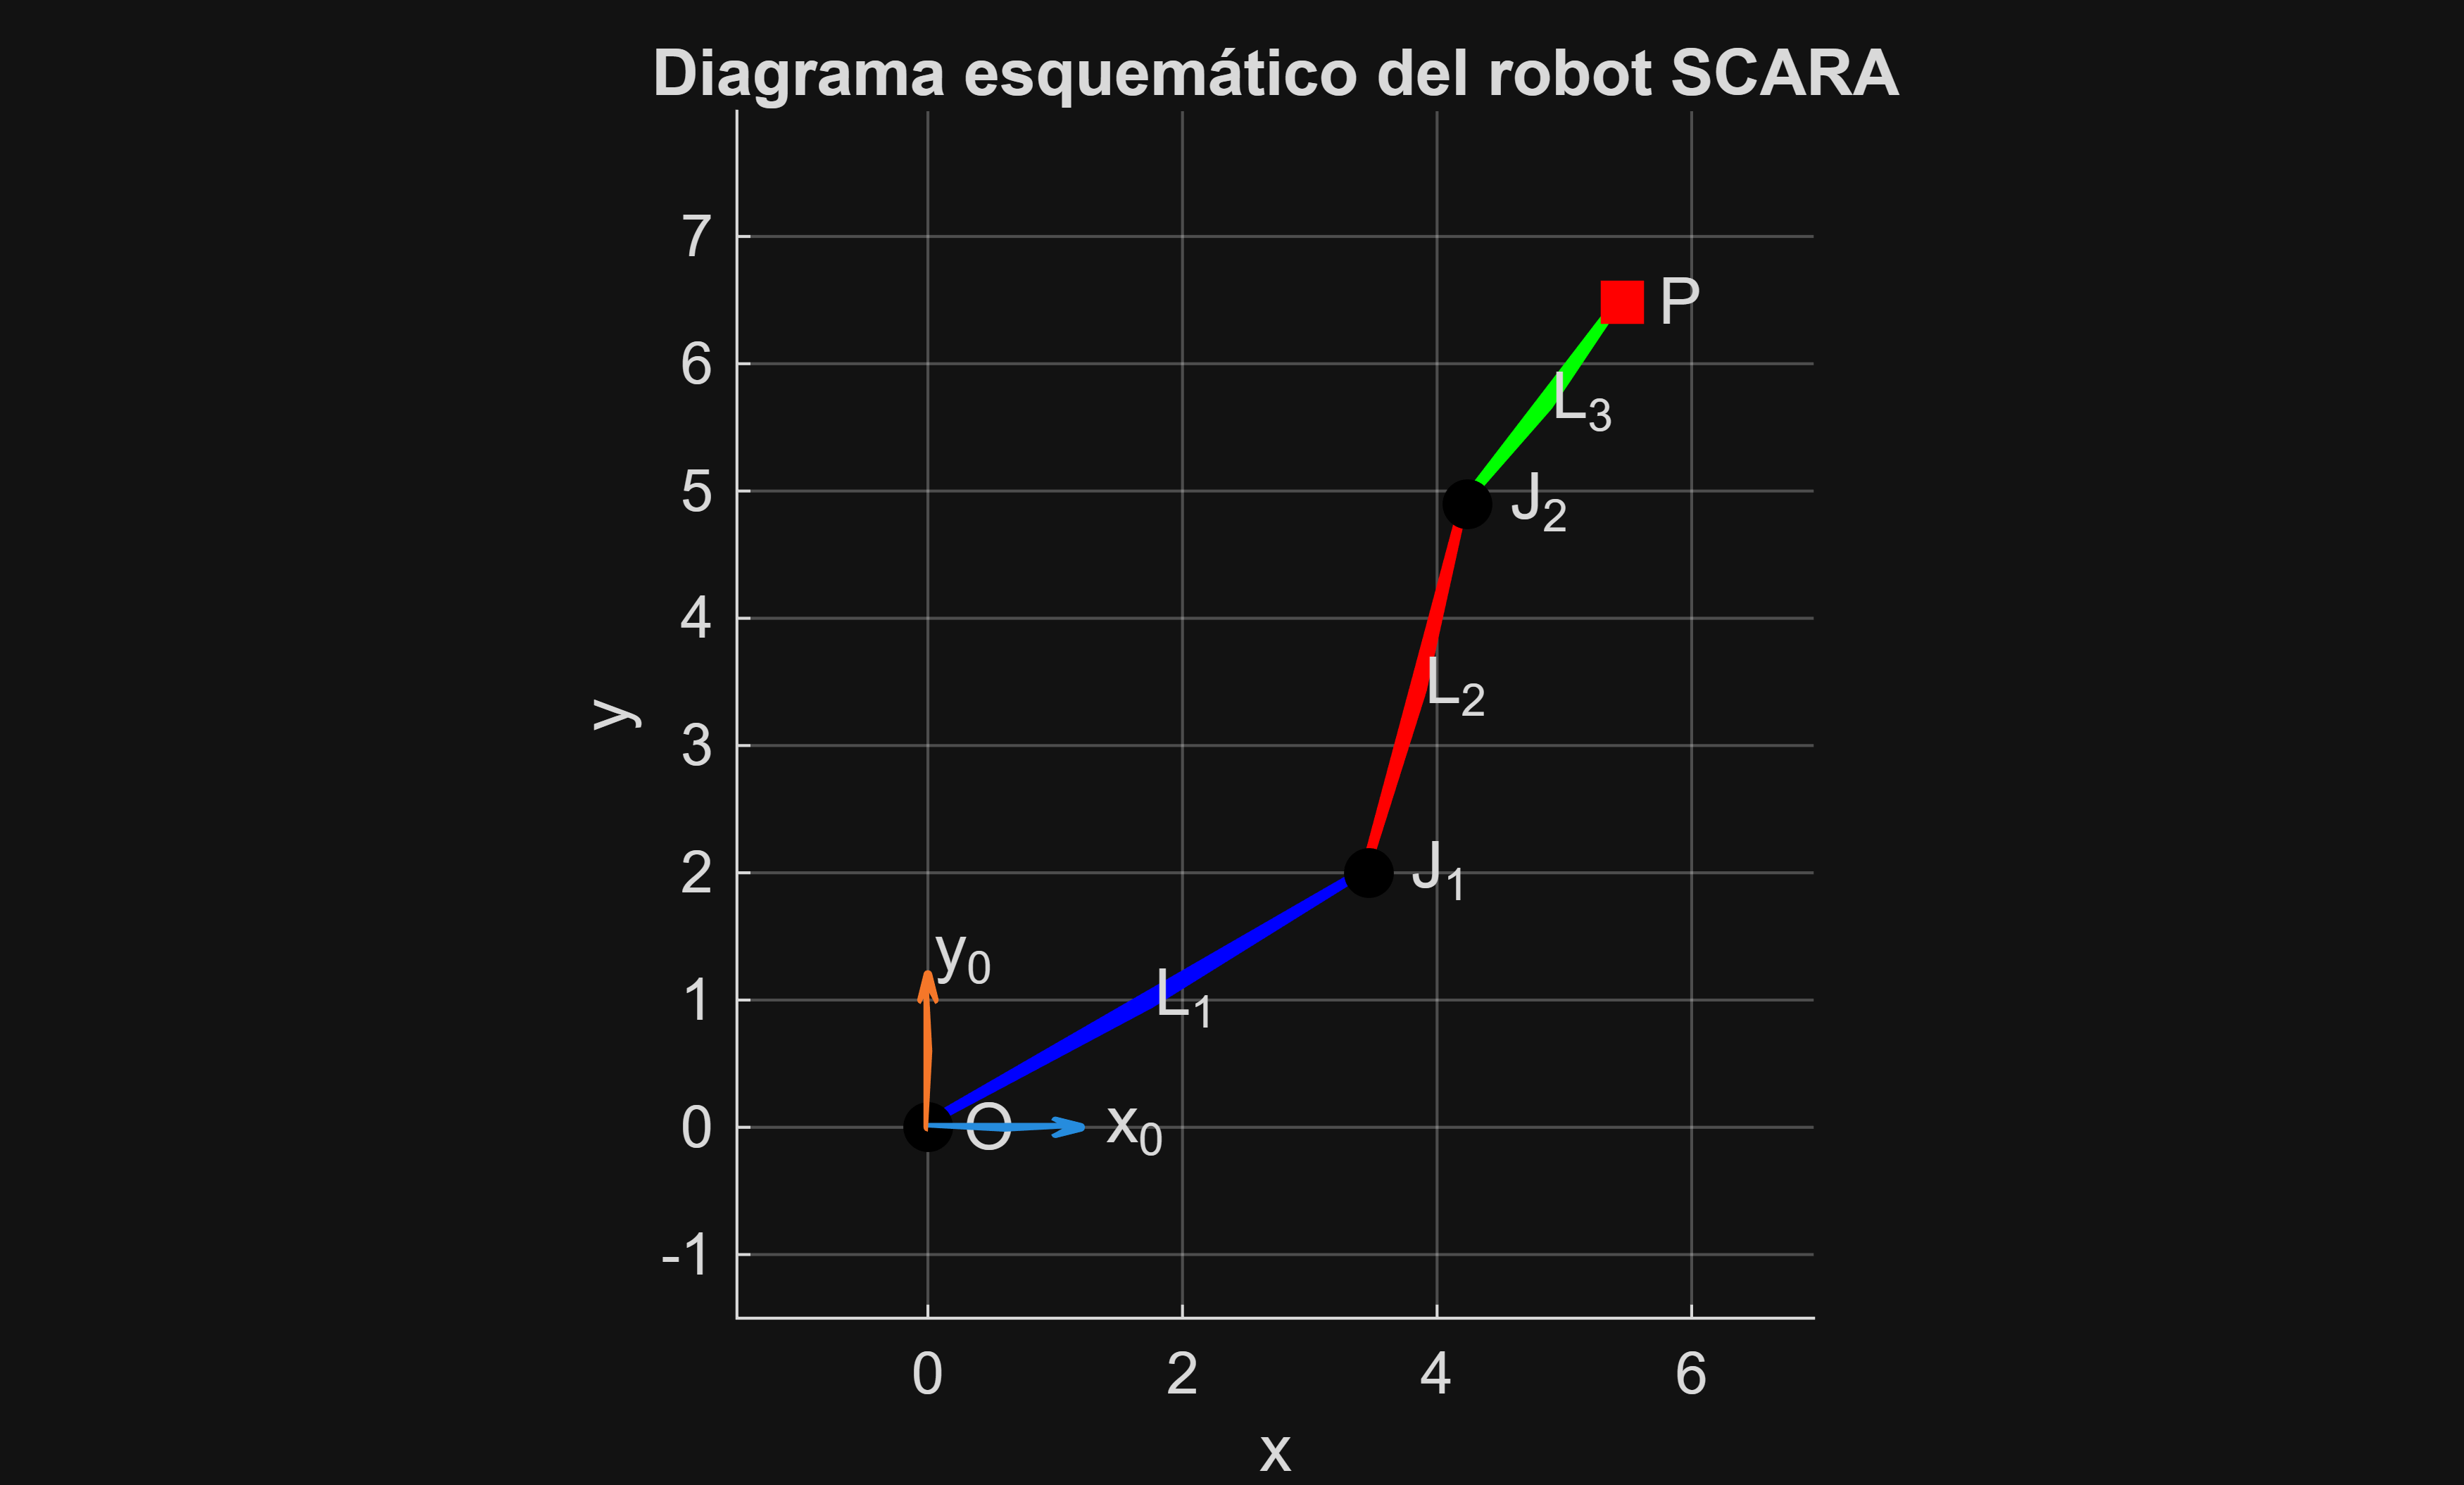

In [2]:
%% Figura del robot SCARA


% Valores numéricos de ejemplo solo para visualización
L1_fig = 4;
L2_fig = 3;
L3_fig = 2;


theta1_fig = pi/6;
theta2_fig = pi/4;
theta3_fig = -pi/8;


% Posiciones de las articulaciones y del efector final
O  = [0, 0];
J1 = [L1_fig*cos(theta1_fig), ...
    L1_fig*sin(theta1_fig)];


J2 = [J1(1) + L2_fig*cos(theta1_fig + theta2_fig), ...
    J1(2) + L2_fig*sin(theta1_fig + theta2_fig)];


P  = [J2(1) + L3_fig*cos(theta1_fig + theta2_fig + theta3_fig), ...
    J2(2) + L3_fig*sin(theta1_fig + theta2_fig + theta3_fig)];


figure
hold on
grid on
axis equal


% Eslabones
plot([O(1) J1(1)], [O(2) J1(2)], '-', 'LineWidth', 3, 'Color', 'b') % L1 de color Azul ('b')
plot([J1(1) J2(1)], [J1(2) J2(2)], '-', 'LineWidth', 3, 'Color', 'r') % L2 de color Rojo ('r')
plot([J2(1) P(1)],  [J2(2) P(2)],  '-', 'LineWidth', 3, 'Color', 'g') % L3 de color Verde ('g')


% Articulaciones y efector
plot(O(1),  O(2),  'ko', 'MarkerSize', 8, 'MarkerFaceColor', 'k')
plot(J1(1), J1(2), 'ko', 'MarkerSize', 8, 'MarkerFaceColor', 'k')
plot(J2(1), J2(2), 'ko', 'MarkerSize', 8, 'MarkerFaceColor', 'k')
plot(P(1),  P(2),  'rs', 'MarkerSize', 9, 'MarkerFaceColor', 'r')


% Etiquetas de puntos
text(O(1),  O(2),  '  O',  'FontSize', 11)
text(J1(1), J1(2), '  J_1', 'FontSize', 11)
text(J2(1), J2(2), '  J_2', 'FontSize', 11)
text(P(1),  P(2),  '  P',  'FontSize', 11)


% Etiquetas de eslabones
text((O(1)+J1(1))/2,   (O(2)+J1(2))/2,   'L_1', 'FontSize', 11)
text((J1(1)+J2(1))/2,  (J1(2)+J2(2))/2,  'L_2', 'FontSize', 11)
text((J2(1)+P(1))/2,   (J2(2)+P(2))/2,   'L_3', 'FontSize', 11)


% Ejes globales
quiver(0,0,1.2,0,0, 'LineWidth', 1.5, 'MaxHeadSize', 0.5)
quiver(0,0,0,1.2,0, 'LineWidth', 1.5, 'MaxHeadSize', 0.5)
text(1.35,0,'x_0','FontSize',11)
text(0,1.35,'y_0','FontSize',11)


% Título y ejes
xlabel('x')
ylabel('y')
title('Diagrama esquemático del robot SCARA')


% Ajuste visual
xlim([min([O(1),J1(1),J2(1),P(1)])-1.5, max([O(1),J1(1),J2(1),P(1)])+1.5])
ylim([min([O(2),J1(2),J2(2),P(2)])-1.5, max([O(2),J1(2),J2(2),P(2)])+1.5])


% Guardar imagen por si la quieres reutilizar
saveas(gcf,'diagrama_scara.png')


### Planteamiento del modelo cinemático de la posición


In [3]:
syms x_O_1 y_O_1 theta_O_1 L_2 theta_1_2 L_3 theta_2_3 L_1 x_d y_d phi_d


T_O_1 = Tij(x_O_1,y_O_1,0,0,0,theta_O_1);
T_1_2 = Tij(L_1,0,0,0,0,theta_1_2)

In [4]:
T_2_3 = Tij(L_2,0,0,0,0,theta_2_3)

In [5]:
T_3_P = Tij(L_3,0,0,0,0,0)

In [6]:


T_O_P = simplify(T_O_1*T_1_2*T_2_3*T_3_P)


Vector de postura del robot


In [7]:
xi_O_P = [T_O_P(1,4);T_O_P(2,4);theta_O_1+theta_1_2+theta_2_3]


El resultado anterior corresponde al modelo cinemático directo de la postura del robot, ya que permite obtener la posición y orientación del efector final a partir de las variables articulares.

Para el modelo cinemático inverso de la postura, el problema consiste en determinar los valores articulares necesarios para alcanzar una postura deseada del efector final. Para ello se parte de una postura objetivo definida por las coordenadas x\_d, y\_d y la orientación phi\_d.

Primero se calcula la posición de la muñeca, eliminando la contribución geométrica del último eslabón. Después, mediante relaciones trigonométricas, se obtiene el valor de las articulaciones que permiten alcanzar dicha postura.


In [8]:
%% Modelo cinemático inverso de la postura


% Posición de la muñeca
x_w = simplify(x_d - x_O_1 - L_3*cos(phi_d));
y_w = simplify(y_d - y_O_1 - L_3*sin(phi_d));


% Término auxiliar
c2 = simplify((x_w^2 + y_w^2 - L_1^2 - L_2^2)/(2*L_1*L_2));


% Dos posibles configuraciones
s2_pos = simplify(sqrt(1 - c2^2));
s2_neg = simplify(-sqrt(1 - c2^2));


theta_1_2_sol1 = simplify(atan2(s2_pos, c2));
theta_1_2_sol2 = simplify(atan2(s2_neg, c2));


theta_O_1_sol1 = simplify(atan2(y_w, x_w) - atan2(L_2*s2_pos, L_1 + L_2*c2));
theta_O_1_sol2 = simplify(atan2(y_w, x_w) - atan2(L_2*s2_neg, L_1 + L_2*c2));


theta_2_3_sol1 = simplify(phi_d - theta_O_1_sol1 - theta_1_2_sol1);
theta_2_3_sol2 = simplify(phi_d - theta_O_1_sol2 - theta_1_2_sol2);


% Soluciones de la cinemática inversa
q_inv_sol1 = simplify([theta_O_1_sol1; theta_1_2_sol1; theta_2_3_sol1])

In [9]:
q_inv_sol2 = simplify([theta_O_1_sol2; theta_1_2_sol2; theta_2_3_sol2])

In [10]:
% Verificación de las soluciones
xi_verificacion_sol1 = simplify(subs(xi_O_P, ...
    [theta_O_1, theta_1_2, theta_2_3], ...
    [q_inv_sol1(1), q_inv_sol1(2), q_inv_sol1(3)]))

In [11]:
xi_verificacion_sol2 = simplify(subs(xi_O_P, ...
    [theta_O_1, theta_1_2, theta_2_3], ...
    [q_inv_sol2(1), q_inv_sol2(2), q_inv_sol2(3)]))


Las expresiones anteriores representan el modelo cinemático inverso de la postura. Debe observarse que existen dos soluciones posibles, asociadas a las configuraciones conocidas como codo arriba y codo abajo. Esto significa que una misma postura del efector final puede alcanzarse con diferentes configuraciones articulares.

La verificación simbólica permite comprobar que, al sustituir las soluciones obtenidas en el modelo cinemático directo, se recupera la postura deseada del efector final. De esta manera se valida la consistencia del modelo desarrollado.

### Modelo cinemático directo de las velocidades

Una vez obtenida la postura del efector final, el siguiente paso consiste en relacionar las velocidades articulares con la velocidad lineal y angular del robot. Para ello se utiliza la matriz Jacobiana, la cual se obtiene derivando el vector de postura con respecto a las variables articulares.

El modelo cinemático directo de velocidades permite calcular la velocidad del efector final a partir de las velocidades articulares. Por otro lado, el modelo cinemático inverso de velocidades permite obtener las velocidades articulares necesarias para producir una velocidad deseada del efector final, siempre y cuando la matriz Jacobiana no se encuentre en una configuración singular.


In [12]:
% Variables simbólicas de velocidad articular y velocidad deseada del efector
syms dtheta_O_1 dtheta_1_2 dtheta_2_3 real
syms x_dot_d y_dot_d phi_dot_d real


% Vectores articulares
q = [theta_O_1; theta_1_2; theta_2_3];
q_dot = [dtheta_O_1; dtheta_1_2; dtheta_2_3];


% Jacobiano del robot
J_O_P = simplify(jacobian(xi_O_P, q))

In [13]:
% Modelo cinemático directo de velocidades
xi_dot_O_P = simplify(J_O_P*q_dot)

In [14]:
det_J_O_P = simplify(det(J_O_P))


### Modelo cinemático inverso de las velocidades

In [15]:
% Velocidad deseada del efector final
xi_dot_d = [x_dot_d; y_dot_d; phi_dot_d];


% Modelo cinemático inverso de velocidades
J_O_P_inv = simplify(inv(J_O_P));
q_dot_inv = simplify(J_O_P_inv*xi_dot_d)


La matriz Jacobiana obtenida permite expresar de forma compacta la relación entre las velocidades articulares y la velocidad del efector final. De esta manera, el modelo cinemático directo de velocidades queda definido por la multiplicación de la matriz Jacobiana por el vector de velocidades articulares.

El modelo cinemático inverso de velocidades se obtiene al invertir la matriz Jacobiana. Este procedimiento solo es válido cuando el determinante del Jacobiano es distinto de cero, es decir, cuando el robot no se encuentra en una configuración singular. En este caso, el determinante permite identificar directamente las condiciones bajo las cuales el modelo inverso deja de ser aplicable.

### Modelo cinemático de las aceleaciones


In [16]:
% Variables simbólicas de aceleración articular y aceleración deseada
syms ddtheta_O_1 ddtheta_1_2 ddtheta_2_3 real
syms x_ddot_d y_ddot_d phi_ddot_d real


% Vector de aceleraciones articulares
q_ddot = [ddtheta_O_1; ddtheta_1_2; ddtheta_2_3];


% Jacobiano derivado respecto al tiempo
J_dot_O_P = simplify( ...
    diff(J_O_P, theta_O_1)*dtheta_O_1 + ...
    diff(J_O_P, theta_1_2)*dtheta_1_2 + ...
    diff(J_O_P, theta_2_3)*dtheta_2_3 );
% Modelo cinemático directo de aceleraciones
xi_ddot_O_P = simplify(J_O_P*q_ddot + J_dot_O_P*q_dot)

In [17]:
xi_ddot_d = [x_ddot_d; y_ddot_d; phi_ddot_d];


% Modelo cinemático inverso de aceleraciones
q_ddot_inv = simplify(J_O_P_inv*(xi_ddot_d - J_dot_O_P*q_dot))


El análisis cinemático de aceleraciones permite relacionar las aceleraciones articulares con la aceleración lineal y angular del efector final. Para ello se deriva con respecto al tiempo el modelo cinemático de velocidades.

El modelo cinemático directo de aceleraciones se obtiene a partir de la derivada temporal del producto entre la matriz Jacobiana y el vector de velocidades articulares. Esto da lugar a dos contribuciones: una asociada directamente a las aceleraciones articulares y otra asociada a la variación temporal de la matriz Jacobiana debido al movimiento del propio robot.

Por otra parte, el modelo cinemático inverso de aceleraciones permite despejar las aceleraciones articulares necesarias para producir una aceleración deseada en el efector final, operando con la inversa del Jacobiano.

### Modelo dinámico por ecuaciones de Eüler\-Lagrange

Se emplearan las siguientes ecuaciones para el cálculo de la energía cinética:

$$\mathrm{\,}$$

$$k_i =\frac{m_i }{2}{\mathbf{v}}_{C_i }^T {\mathbf{v}}_{C_i } +\frac{1}{2}{\mathbf{\omega }}_{C_i }^T {\mathbf{I}}_{C_i } {\mathbf{\omega }}_{C_i }$$


In [18]:
syms x_1_C1 theta_dot_O_1


v_C1_C1 = [0;x_1_C1*theta_dot_O_1;0]

In [19]:


v_O_C1 = [-x_1_C1*sin(theta_O_1)*theta_dot_O_1;x_1_C1*cos(theta_O_1)*theta_dot_O_1;0]

In [20]:
transpose(v_C1_C1)*v_C1_C1

In [21]:
simplify(transpose(v_O_C1)*v_O_C1)


## Cálculo de la posición de los centros de masa

Para formular el balance energético del sistema se requiere conocer la ubicación espacial del centro de masa de cada eslabón respecto al marco de referencia de la base. Esto se logra multiplicando las matrices de transformación homogénea sucesivas de cada articulación por una traslación local sobre el eje longitudinal del eslabón correspondiente.

Aplicando derivadas parciales con respecto a las coordenadas generalizadas, se obtienen los vectores de velocidad lineal absoluta para cada centro de masa. Por su parte, las velocidades angulares de cada eslabón se calculan mediante una propagación rotacional sucesiva sobre el eje de rotación de cada articulación.


In [22]:
syms x_1_C1 x_2_C2 x_3_C3


T_1_C1 = Tij(x_1_C1,0,0,0,0,0)

In [23]:
T_O_C1 = T_O_1*T_1_C1

In [24]:


T_2_C2 = Tij(x_2_C2,0,0,0,0,0)

In [25]:
T_O_C2 = T_O_1*T_1_2*T_2_C2

In [26]:


T_3_C3 = Tij(x_3_C3,0,0,0,0,0)

In [27]:
T_O_C3 = T_O_1*T_1_2*T_2_3*T_3_C3

In [28]:


%Vectores de posición
p_O_C1 = [T_O_C1(1,4);T_O_C1(2,4);T_O_C1(3,4)]

In [29]:
p_O_C2 = simplify([T_O_C2(1,4);T_O_C2(2,4);T_O_C2(3,4)])

In [30]:


p_O_C3 = simplify([T_O_C3(1,4);T_O_C3(2,4);T_O_C3(3,4)])


## Cálculo de las velocidades


In [31]:
syms theta_dot_O_1 theta_dot_1_2 theta_dot_2_3


v_O_C1 = diff(p_O_C1,theta_O_1)*theta_dot_O_1+diff(p_O_C1,theta_1_2)*theta_dot_1_2+diff(p_O_C1,theta_2_3)*theta_dot_2_3

In [32]:
v_O_C2 = diff(p_O_C2,theta_O_1)*theta_dot_O_1+diff(p_O_C2,theta_1_2)*theta_dot_1_2+diff(p_O_C2,theta_2_3)*theta_dot_2_3

In [33]:
v_O_C3 = diff(p_O_C3,theta_O_1)*theta_dot_O_1+diff(p_O_C3,theta_1_2)*theta_dot_1_2+diff(p_O_C3,theta_2_3)*theta_dot_2_3


Cálculo de la velocidades angulares


In [34]:
syms omega_1_1 omega_2_2 omega_3_3
%Propagación para el primer cuerpo
omega_1_1

In [35]:
omega_O_O = [0;0;0]

omega_O_O = 3x1
     0
     0
     0

In [36]:
n_1_1 = [0;0;1]

n_1_1 = 3x1
     0
     0
     1

In [37]:
R_O_1 = [T_O_1(1,1),T_O_1(1,2),T_O_1(1,3);T_O_1(2,1),T_O_1(2,2),T_O_1(2,3);T_O_1(3,1),T_O_1(3,2),T_O_1(3,3)]

In [38]:
R_1_O = transpose(R_O_1)

In [39]:


%Ecuación de propagación
omega_1_1 = R_1_O*omega_O_O+n_1_1*theta_dot_O_1

In [40]:


%Propagación para el segundo cuerpo
omega_2_2

In [41]:
n_2_2 = [0;0;1]

n_2_2 = 3x1
     0
     0
     1

In [42]:
R_1_2 = [T_1_2(1,1),T_1_2(1,2),T_1_2(1,3);T_1_2(2,1),T_1_2(2,2),T_1_2(2,3);T_1_2(3,1),T_1_2(3,2),T_1_2(3,3)]

In [43]:
R_2_1 = transpose(R_1_2)

In [44]:


%Ecuación de propagación
omega_2_2 = R_2_1*omega_1_1+n_2_2*theta_dot_1_2

In [45]:


%Propagación para el tercer cuerpo
omega_3_3

In [46]:
n_3_3 = [0;0;1]

n_3_3 = 3x1
     0
     0
     1

In [47]:
R_2_3 = [T_2_3(1,1),T_2_3(1,2),T_2_3(1,3);T_2_3(2,1),T_2_3(2,2),T_2_3(2,3);T_2_3(3,1),T_2_3(3,2),T_2_3(3,3)]

In [48]:
R_3_2 = transpose(R_2_3)

In [49]:


%Ecuación de propagación
omega_3_3 = R_3_2*omega_2_2+n_3_3*theta_dot_2_3

In [50]:
v_O_C3


## Defición de los elementos de inercia


In [51]:
syms g I_xx1 I_yy1 I_zz1 I_xx2 I_yy2 I_zz2 I_xx3 I_yy3 I_zz3
%vector de gravedad


g_v = [0;-g;0]

In [52]:


I_C1 = [I_xx1,0,0;0,I_yy1,0;0,0,I_zz1]

In [53]:
I_C2 = [I_xx2,0,0;0,I_yy2,0;0,0,I_zz2]

In [54]:
I_C3 = [I_xx3,0,0;0,I_yy3,0;0,0,I_zz3]


Cáculo del Lagrangeano


In [55]:
syms m_1 m_2 m_3
%energía cinética de cada uno de los cuerpos


k_1 = simplify((m_1/2)*transpose(v_O_C1)*v_O_C1+(1/2)*transpose(omega_1_1)*I_C1*omega_1_1)

In [56]:


k_2 = simplify((m_2/2)*transpose(v_O_C2)*v_O_C2+(1/2)*transpose(omega_2_2)*I_C2*omega_2_2)

In [57]:


k_3 = simplify((m_3/2)*transpose(v_O_C3)*v_O_C3+(1/2)*transpose(omega_3_3)*I_C3*omega_3_3)

In [58]:
% Cáclulo de la energía potencial de cada cuerpo


u_1 = -m_1*transpose(p_O_C1)*g_v

In [59]:
u_2 = -m_2*transpose(p_O_C2)*g_v

In [60]:
u_3 = -m_3*transpose(p_O_C3)*g_v


Cálculo del Lagrangeano

A partir de las velocidades lineales y angulares, junto con las masas y los momentos de inercia de cada cuerpo rígido, se calculan de manera independiente las energías cinéticas y potenciales de cada eslabón. La función Lagrangiana total del sistema se define matemáticamente como la diferencia entre la energía cinética total y la energía potencial total acumulada.

Aplicando las ecuaciones diferenciales de Euler\-Lagrange para cada coordenada generalizada del sistema, se obtienen las expresiones analíticas de los pares generalizados que actúan en las articulaciones del robot.


In [61]:


La = (k_1+k_2+k_3)-(u_1+u_2+u_3)


## Cálculo de los pares


In [62]:
syms theta_ddot_O_1 theta_ddot_1_2 theta_ddot_2_3


D_theta1 = diff(La,theta_dot_O_1)

In [63]:


% Cálculo de relación


tao_1 = diff(D_theta1,theta_O_1)*theta_dot_O_1 + diff(D_theta1,theta_1_2)*theta_dot_1_2 + diff(D_theta1,theta_2_3)*theta_dot_2_3 + diff(D_theta1,theta_dot_O_1)*theta_ddot_O_1+ diff(D_theta1,theta_dot_1_2)*theta_ddot_1_2+ diff(D_theta1,theta_dot_2_3)*theta_ddot_2_3-diff(La,theta_O_1)

In [64]:


D_theta2 = diff(La,theta_dot_1_2)

In [65]:
tao_2 = diff(D_theta2,theta_O_1)*theta_dot_O_1 + diff(D_theta2,theta_1_2)*theta_dot_1_2 + diff(D_theta2,theta_2_3)*theta_dot_2_3 + diff(D_theta2,theta_dot_O_1)*theta_ddot_O_1+ diff(D_theta2,theta_dot_1_2)*theta_ddot_1_2+ diff(D_theta2,theta_dot_2_3)*theta_ddot_2_3-diff(La,theta_1_2)

In [66]:


D_theta3 = diff(La,theta_dot_2_3)

In [67]:
tao_3 = diff(D_theta3,theta_O_1)*theta_dot_O_1 + diff(D_theta3,theta_1_2)*theta_dot_1_2 + diff(D_theta3,theta_2_3)*theta_dot_2_3 + diff(D_theta3,theta_dot_O_1)*theta_ddot_O_1+ diff(D_theta3,theta_dot_1_2)*theta_ddot_1_2+ diff(D_theta3,theta_dot_2_3)*theta_ddot_2_3-diff(La,theta_2_3)

In [68]:


tao = [tao_1;tao_2;tao_3]

In [69]:
% Cálculo de la matriz de inercia


M1 = subs(tao,[theta_ddot_O_1,theta_ddot_1_2,theta_ddot_2_3,theta_dot_O_1,theta_dot_1_2,theta_dot_2_3,g],[1,0,0,0,0,0,0])

In [70]:
M2 = subs(tao,[theta_ddot_O_1,theta_ddot_1_2,theta_ddot_2_3,theta_dot_O_1,theta_dot_1_2,theta_dot_2_3,g],[0,1,0,0,0,0,0])

In [71]:
M3 = subs(tao,[theta_ddot_O_1,theta_ddot_1_2,theta_ddot_2_3,theta_dot_O_1,theta_dot_1_2,theta_dot_2_3,g],[0,0,1,0,0,0,0])

In [72]:


M_theta = collect([M1 M2 M3],[m_1,m_2,m_3])


Cálculo del vector de pares de


In [73]:
V_theta = subs(tao,[theta_ddot_O_1,theta_ddot_1_2,theta_ddot_2_3,theta_dot_O_1,theta_dot_1_2,theta_dot_2_3,g],[0,0,0,theta_dot_O_1,theta_dot_1_2,theta_dot_2_3,0])

In [74]:
G_theta = subs(tao,[theta_ddot_O_1,theta_ddot_1_2,theta_ddot_2_3,theta_dot_O_1,theta_dot_1_2,theta_dot_2_3,g],[0,0,0,0,0,0,g])


Cálculo del modelo  Dinámico inverso


In [75]:
%% Modelo dinámico inverso en forma matricial compacta
syms theta_ddot_0_1 theta_ddot_1_2 theta_ddot_2_3 real
theta_ddot_vec = [theta_ddot_0_1; theta_ddot_1_2; theta_ddot_2_3];


% Simplificamos previamente los componentes matriciales obtenidos
M_theta_s = simplify(M_theta);
V_theta_s = simplify(V_theta);
G_theta_s = simplify(G_theta);


% Ecuación matricial de pares (Dinámica Inversa)
tao_matricial = simplify(M_theta_s * theta_ddot_vec + V_theta_s + G_theta_s)

In [76]:


%% Cálculo del modelo Dinámico directo (Despeje de aceleraciones articulares)
syms tau_ext_1 tau_ext_2 tau_ext_3 real
tau_ext = [tau_ext_1; tau_ext_2; tau_ext_3];


% Aceleraciones articulares producidas por un vector de pares aplicados
theta_ddot_dinamico = simplify(M_theta_s \ (tau_ext - V_theta_s - G_theta_s))


Conclusiones

Durante este reporte se realizó el modelado cinemático y dinámico de un robot manipulador tipo SCARA, utilizando los temas vistos en clase. Primero, se obtuvo el modelo cinemático directo mediante matrices de transformación homogénea, con el que se pudo calcular la posición y orientación del efector final a partir de las variables de las articulaciones. Después, se desarrolló el modelo cinemático inverso, que permite encontrar los valores de las articulaciones necesarios para llegar a una posición y orientación deseadas.

Posteriormente, se calcularon las velocidades y aceleraciones del robot. Para ello, se utilizó la matriz Jacobiana, que relaciona el movimiento de las articulaciones con el movimiento del efector final. También se revisó el determinante de esta matriz para identificar las posiciones singulares, en las que el robot presenta limitaciones para realizar ciertos movimientos y el cálculo inverso no puede aplicarse directamente.

Por último, se obtuvo el modelo dinámico del robot mediante el método de Euler-Lagrange, tomando en cuenta las energías cinética y potencial de sus eslabones. Con este método se obtuvieron las ecuaciones que describen el movimiento del robot y los pares necesarios en sus articulaciones. Estos resultados pueden utilizarse para realizar simulaciones, planear movimientos y desarrollar sistemas de control.

Con los resultados obtenidos, se concluye que las matrices de transformación homogénea, la matriz Jacobiana y las ecuaciones de Euler-Lagrange permiten describir el comportamiento del robot desde diferentes aspectos. De esta manera, se cumplió el objetivo del reporte, ya que se logró relacionar las variables de las articulaciones con la posición, orientación, velocidad, aceleración y los pares del robot.

De manera personal, este trabajo me ayudó a entender mejor cómo funcionan los modelos matemáticos aplicados a los robots. También comprendí que no se trata solamente de obtener ecuaciones, sino de entender qué representa cada una y cómo se relaciona con el movimiento real del sistema. Por ello, considero que desarrollar estos modelos es importante para poder simular, analizar y controlar robots manipuladores en aplicaciones de ingeniería mecatrónica.
